# UTS Intelegensi Buatan
# Klasifikasi Kultivar Anggur (Kasus 1)

**Nama:** Nazwa Khoerunnisa  
**NIM:** 23552011093  
**Mata kuliah:** Intelegensi Buatan
**Dataset:** `kasus01_wine.csv` (178 sampel, 13 fitur kimia, target `kultivar`: Kultivar A, B, C)


In [1]:
import os
import sys
import json
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

SEED = 42
os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)

NIM = "23552011093"
jumlah_digit = sum(int(d) for d in NIM)
sisa = jumlah_digit % 10
kasus = 10 if sisa == 0 else sisa
print(f"NIM {NIM}: jumlah digit = {'+'.join(NIM)} = {jumlah_digit}")
print(f"{jumlah_digit} mod 10 = {sisa}  ->  Kasus {kasus}")
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)

NIM 23552011093: jumlah digit = 2+3+5+5+2+0+1+1+0+9+3 = 31
31 mod 10 = 1  ->  Kasus 1
scikit-learn: 1.6.1 | pandas: 2.2.3


In [2]:
DATASET_PATH = os.path.join("dataset", "kasus01_wine.csv")
URL_DATASET = ("https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/"
               "Artificial-Intelegent-Course-Bank/main/UTS/dataset/kasus01_wine.csv")

# Kalau file di-upload langsung ke sidebar Colab (folder /content), pindahkan ke folder dataset/
if not os.path.exists(DATASET_PATH) and os.path.exists("kasus01_wine.csv"):
    os.replace("kasus01_wine.csv", DATASET_PATH)

if not os.path.exists(DATASET_PATH):
    try:
        import urllib.request
        urllib.request.urlretrieve(URL_DATASET, DATASET_PATH)
        print("Dataset berhasil diunduh dari repositori dosen.")
    except Exception as e:
        print("Unduhan otomatis gagal:", e)
        try:
            from google.colab import files
            print("Silakan pilih file kasus01_wine.csv dari komputer Anda...")
            hasil_upload = files.upload()
            for nama in hasil_upload:
                os.replace(nama, DATASET_PATH)
                break
        except ImportError:
            raise FileNotFoundError(
                "Letakkan file kasus01_wine.csv di folder dataset/ lalu jalankan ulang cell ini.")

df = pd.read_csv(DATASET_PATH)
print("Ukuran data:", df.shape)
df.head()

Dataset berhasil diunduh dari repositori dosen.
Ukuran data: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315_of_diluted_wines,proline,kultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,Kultivar A
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,Kultivar A
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,Kultivar A
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,Kultivar A
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,Kultivar A


In [3]:
TARGET = "kultivar"
FITUR_ASLI = [c for c in df.columns if c != TARGET]

print("=== Tipe data ===")
print(df.dtypes.to_string())

print("\n=== Missing value per kolom ===")
print(df.isna().sum().to_string())
print("Total missing:", int(df.isna().sum().sum()))

jumlah_duplikat = int(df.duplicated().sum())
print("\nBaris duplikat:", jumlah_duplikat)
if jumlah_duplikat > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplikat dibuang, ukuran baru:", df.shape)

print("\n=== Distribusi kelas target ===")
dist = df[TARGET].value_counts()
print(pd.DataFrame({"jumlah": dist, "persen": (dist / len(df) * 100).round(1)}).to_string())

print("\n=== Ringkasan statistik fitur ===")
df[FITUR_ASLI].describe().T.round(2)

=== Tipe data ===
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280_od315_of_diluted_wines    float64
proline                         float64
kultivar                         object

=== Missing value per kolom ===
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280_od315_of_

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [4]:
# Pemeriksaan nilai tidak wajar
print("Jumlah nilai negatif per kolom (harus 0 untuk ukuran kimia):")
print((df[FITUR_ASLI] < 0).sum().to_string())
print("\nJumlah nilai nol per kolom:")
print((df[FITUR_ASLI] == 0).sum().to_string())

# Pemeriksaan logika: flavanoid adalah bagian dari total fenol
n_lebih = int((df["flavanoids"] > df["total_phenols"]).sum())
print(f"\nBaris dengan flavanoids > total_phenols: {n_lebih}")

# Hitung pencilan dengan aturan IQR (hanya untuk dilihat, tidak dibuang)
q1, q3 = df[FITUR_ASLI].quantile(0.25), df[FITUR_ASLI].quantile(0.75)
iqr = q3 - q1
pencilan = ((df[FITUR_ASLI] < (q1 - 1.5 * iqr)) | (df[FITUR_ASLI] > (q3 + 1.5 * iqr))).sum()
print("\nJumlah pencilan (aturan IQR) per kolom:")
print(pencilan[pencilan > 0].to_string())

Jumlah nilai negatif per kolom (harus 0 untuk ukuran kimia):
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280_od315_of_diluted_wines    0
proline                         0

Jumlah nilai nol per kolom:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280_od315_of_diluted_wines    0
proline                         0

Baris dengan flavanoids >

In [5]:
X = df[FITUR_ASLI]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nProporsi kelas (train vs test):")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True).round(3),
    "test": y_test.value_counts(normalize=True).round(3),
}).to_string())

X_train: (142, 13) | X_test: (36, 13)

Proporsi kelas (train vs test):
            train   test
kultivar                
Kultivar B  0.401  0.389
Kultivar A  0.331  0.333
Kultivar C  0.268  0.278


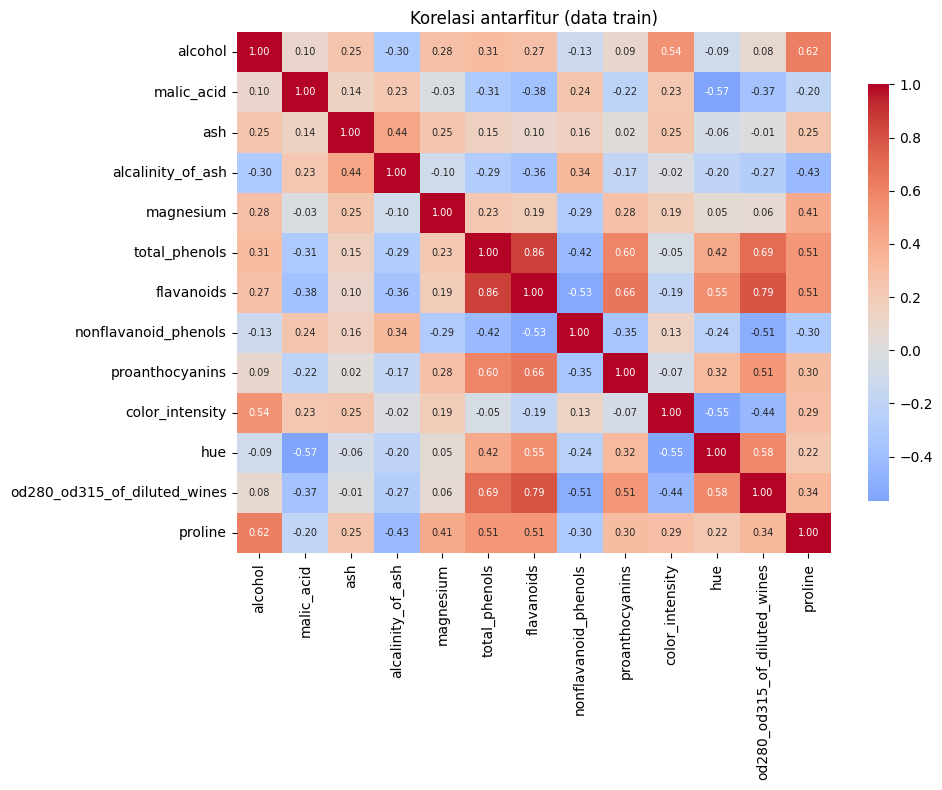

,fitur_1,fitur_2,korelasi
0,total_phenols,flavanoids,0.861
1,flavanoids,od280_od315_of_diluted_wines,0.786
2,total_phenols,od280_od315_of_diluted_wines,0.695
3,flavanoids,proanthocyanins,0.657
4,alcohol,proline,0.621


In [6]:
korelasi = X_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Korelasi antarfitur (data train)")
plt.tight_layout()
plt.show()

# Daftar pasangan fitur dengan |korelasi| tinggi
pasangan = []
for i, a in enumerate(FITUR_ASLI):
    for b in FITUR_ASLI[i + 1:]:
        r = korelasi.loc[a, b]
        if abs(r) >= 0.60:
            pasangan.append((a, b, round(r, 3)))
tabel_pasangan = pd.DataFrame(pasangan, columns=["fitur_1", "fitur_2", "korelasi"])
tabel_pasangan.sort_values("korelasi", ascending=False, key=abs).reset_index(drop=True)

In [7]:
%%writefile fitur.py
"""fitur.py - fungsi feature engineering untuk Kasus 1 (Wine, target kultivar)."""
import pandas as pd

TARGET = "kultivar"

FITUR_ASLI = [
    "alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
    "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
    "color_intensity", "hue", "od280_od315_of_diluted_wines", "proline",
]

# Fitur yang berkorelasi tinggi dan informasinya sudah terwakili oleh fitur rasio
FITUR_REDUNDAN = ["total_phenols", "od280_od315_of_diluted_wines"]

MODE_FITUR = ("asli", "tambah", "tambah_buang")
EPS = 1e-9  # mencegah pembagian dengan nol


def tambah_fitur(X, mode="tambah_buang"):
    """Menambah fitur rasio (dan opsional membuang fitur redundan).

    Operasi dilakukan per baris tanpa mempelajari statistik data,
    sehingga aman dipakai di dalam pipeline (tidak ada data leakage).
    """
    if mode not in MODE_FITUR:
        raise ValueError(f"mode harus salah satu dari {MODE_FITUR}")

    if isinstance(X, pd.DataFrame):
        X = X[FITUR_ASLI].copy()
    else:
        X = pd.DataFrame(X, columns=FITUR_ASLI)

    if mode == "asli":
        return X

    X["rasio_flavanoid_fenol"] = X["flavanoids"] / (X["total_phenols"] + EPS)
    X["rasio_od280_flavanoid"] = X["od280_od315_of_diluted_wines"] / (X["flavanoids"] + EPS)
    X["rasio_proline_alkohol"] = X["proline"] / (X["alcohol"] + EPS)

    if mode == "tambah_buang":
        X = X.drop(columns=FITUR_REDUNDAN)
    return X

Writing fitur.py


In [8]:
import importlib
import fitur
importlib.reload(fitur)
from fitur import tambah_fitur, FITUR_REDUNDAN

contoh = tambah_fitur(X_train, mode="tambah")
print("Jumlah fitur per mode:",
      {m: tambah_fitur(X_train, mode=m).shape[1] for m in fitur.MODE_FITUR})

# Apakah rasio memberi informasi? Lihat rata-rata per kultivar (data train)
rasio_cols = ["rasio_flavanoid_fenol", "rasio_od280_flavanoid", "rasio_proline_alkohol"]
print("\nRata-rata fitur rasio per kultivar (data train):")
contoh[rasio_cols].groupby(y_train).mean().round(3)

Jumlah fitur per mode: {'asli': 13, 'tambah': 16, 'tambah_buang': 14}

Rata-rata fitur rasio per kultivar (data train):


,rasio_flavanoid_fenol,rasio_od280_flavanoid,rasio_proline_alkohol
kultivar,,,
Kultivar A,1.041,1.088,79.654
Kultivar B,0.908,1.474,42.936
Kultivar C,0.471,2.559,47.629


In [9]:
def buat_pipeline(model, mode):
    return Pipeline([
        ("fitur", FunctionTransformer(tambah_fitur, kw_args={"mode": mode})),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


def daftar_model():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=7),
    }


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
baris = []
for mode in fitur.MODE_FITUR:
    for nama, model in daftar_model().items():
        hasil = cross_validate(
            buat_pipeline(model, mode), X_train, y_train, cv=cv,
            scoring={"acc": "accuracy", "f1": "f1_macro"}, n_jobs=-1,
        )
        baris.append({
            "varian_fitur": mode, "model": nama,
            "acc_mean": hasil["test_acc"].mean(), "acc_std": hasil["test_acc"].std(),
            "f1_mean": hasil["test_f1"].mean(), "f1_std": hasil["test_f1"].std(),
        })

hasil_cv = pd.DataFrame(baris)
hasil_cv["jumlah_fitur"] = hasil_cv["varian_fitur"].map(
    lambda m: tambah_fitur(X_train.head(1), mode=m).shape[1])

# Aturan pemilihan: F1 macro tertinggi, lalu simpangan baku terkecil,
# lalu jumlah fitur paling sedikit (model lebih sederhana) bila skor masih sama.
hasil_cv = (hasil_cv
            .sort_values(["f1_mean", "f1_std", "jumlah_fitur"], ascending=[False, True, True],
                         key=lambda k: k.round(4) if k.name in ("f1_mean", "f1_std") else k)
            .reset_index(drop=True))
hasil_cv.round(4)

,varian_fitur,model,acc_mean,acc_std,f1_mean,f1_std,jumlah_fitur
0,tambah_buang,SVM (RBF),0.9954,0.0117,0.9959,0.0105,14
1,tambah,SVM (RBF),0.9954,0.0117,0.9959,0.0105,16
2,asli,SVM (RBF),0.9884,0.0207,0.9886,0.0203,13
3,tambah_buang,Logistic Regression,0.9882,0.0212,0.9883,0.0210,14
4,tambah,Logistic Regression,0.9835,0.0219,0.9836,0.0218,16
5,tambah_buang,Random Forest,0.9814,0.0279,0.9828,0.0258,14
6,asli,Logistic Regression,0.9813,0.0216,0.9815,0.0214,13
7,asli,Random Forest,0.9812,0.0253,0.9812,0.0254,13
8,tambah,Random Forest,0.9766,0.0245,0.9767,0.0247,16
9,tambah,KNN,0.9740,0.0242,0.9754,0.0235,16


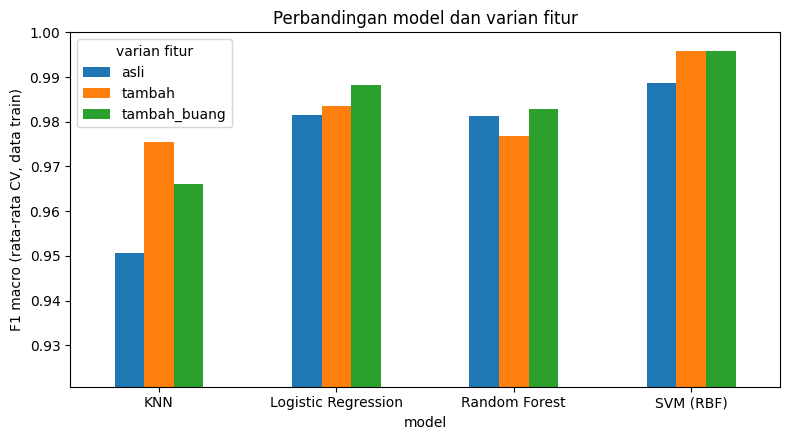

Kombinasi terbaik berdasarkan CV: model = SVM (RBF), varian fitur = tambah_buang
F1 macro CV = 0.9959 (+/- 0.0105), akurasi CV = 0.9954

F1 macro CV untuk model terpilih pada tiap varian fitur:
              jumlah_fitur  f1_mean  f1_std
varian_fitur                               
tambah_buang            14   0.9959  0.0105
tambah                  16   0.9959  0.0105
asli                    13   0.9886  0.0203


In [10]:
# Visualisasi perbandingan F1 macro (rata-rata CV)
pivot = hasil_cv.pivot(index="model", columns="varian_fitur", values="f1_mean")[list(fitur.MODE_FITUR)]
pivot.plot(kind="bar", figsize=(8, 4.5))
plt.ylabel("F1 macro (rata-rata CV, data train)")
plt.title("Perbandingan model dan varian fitur")
plt.ylim(max(0.0, pivot.values.min() - 0.03), 1.0)
plt.xticks(rotation=0)
plt.legend(title="varian fitur")
plt.tight_layout()
plt.show()

terbaik = hasil_cv.iloc[0]
MODE_TERPILIH = terbaik["varian_fitur"]
MODEL_TERPILIH = terbaik["model"]
print(f"Kombinasi terbaik berdasarkan CV: model = {MODEL_TERPILIH}, varian fitur = {MODE_TERPILIH}")
print(f"F1 macro CV = {terbaik['f1_mean']:.4f} (+/- {terbaik['f1_std']:.4f}), "
      f"akurasi CV = {terbaik['acc_mean']:.4f}")

print("\nF1 macro CV untuk model terpilih pada tiap varian fitur:")
print(hasil_cv[hasil_cv.model == MODEL_TERPILIH].set_index("varian_fitur")
      [["jumlah_fitur", "f1_mean", "f1_std"]].round(4).to_string())

Model: SVM (RBF) | varian fitur: tambah_buang

             akurasi: 0.9722
     precision_macro: 0.9778
        recall_macro: 0.9667
            f1_macro: 0.9710
   roc_auc_ovr_macro: 1.0000

Laporan klasifikasi per kelas:
              precision    recall  f1-score   support

  Kultivar A     1.0000    1.0000    1.0000        12
  Kultivar B     0.9333    1.0000    0.9655        14
  Kultivar C     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



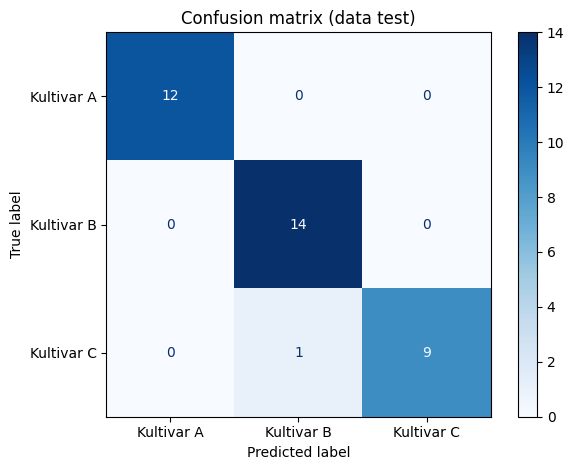

In [11]:
model_final = buat_pipeline(daftar_model()[MODEL_TERPILIH], MODE_TERPILIH)
model_final.fit(X_train, y_train)

# ---- evaluasi di data test: hanya dijalankan satu kali ----
y_pred = model_final.predict(X_test)
y_proba = model_final.predict_proba(X_test)
kelas = list(model_final.classes_)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=kelas)

metrik_test = {"akurasi": float(acc), "precision_macro": float(prec), "recall_macro": float(rec),
               "f1_macro": float(f1), "roc_auc_ovr_macro": float(auc)}
print(f"Model: {MODEL_TERPILIH} | varian fitur: {MODE_TERPILIH}\n")
for k, v in metrik_test.items():
    print(f"{k:>20}: {v:.4f}")

print("\nLaporan klasifikasi per kelas:")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred, labels=kelas)
ConfusionMatrixDisplay(cm, display_labels=kelas).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (data test)")
plt.tight_layout()
plt.show()

In [12]:
MODEL_PATH = os.path.join("models", "wine_model.joblib")

rentang = {c: {"min": float(X_train[c].min()), "max": float(X_train[c].max()),
               "median": float(X_train[c].median())} for c in FITUR_ASLI}
rata_kelas = X_train.groupby(y_train).mean().round(4).to_dict(orient="index")

bundle = {
    "pipeline": model_final,
    "nama_model": MODEL_TERPILIH,
    "varian_fitur": MODE_TERPILIH,
    "fitur_mentah": FITUR_ASLI,
    "kelas": kelas,
    "rentang_fitur": rentang,
    "rata_kelas": rata_kelas,
    "metrik_test": metrik_test,
    "confusion_matrix": cm.tolist(),
    "laporan_klasifikasi": classification_report(y_test, y_pred, output_dict=True, digits=4),
    "hasil_cv": hasil_cv.round(4).to_dict(orient="records"),
    "jumlah_train": int(len(X_train)),
    "jumlah_test": int(len(X_test)),
    "seed": SEED,
    "versi_sklearn": sklearn.__version__,
}
joblib.dump(bundle, MODEL_PATH)

with open(os.path.join("models", "metadata.json"), "w", encoding="utf-8") as f:
    json.dump({k: v for k, v in bundle.items() if k != "pipeline"}, f, indent=2, ensure_ascii=False)

print("Tersimpan:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")
print("Tersimpan:", os.path.join("models", "metadata.json"))

Tersimpan: models/wine_model.joblib (15.6 KB)
Tersimpan: models/metadata.json


In [13]:
# Uji muat ulang: pipeline hasil joblib harus menerima data mentah dan memberi prediksi yang sama
muat = joblib.load(MODEL_PATH)
pipa = muat["pipeline"]

contoh_mentah = X_test.iloc[:5]
prediksi_ulang = pipa.predict(contoh_mentah)
assert (prediksi_ulang == model_final.predict(contoh_mentah)).all(), "Prediksi berbeda setelah dimuat ulang!"

hasil_contoh = pd.DataFrame(pipa.predict_proba(contoh_mentah), columns=muat["kelas"]).round(3)
hasil_contoh.insert(0, "prediksi", prediksi_ulang)
hasil_contoh.insert(0, "asli", y_test.iloc[:5].values)
print("Pipeline hasil joblib berhasil dimuat dan memberi prediksi yang sama.")
hasil_contoh

Pipeline hasil joblib berhasil dimuat dan memberi prediksi yang sama.


,asli,prediksi,Kultivar A,Kultivar B,Kultivar C
0,Kultivar A,Kultivar A,0.976,0.013,0.011
1,Kultivar C,Kultivar C,0.024,0.119,0.857
2,Kultivar A,Kultivar A,0.992,0.004,0.004
3,Kultivar B,Kultivar B,0.108,0.754,0.138
4,Kultivar B,Kultivar B,0.033,0.955,0.012


In [14]:
%%writefile latih.py
"""latih.py - pelatihan, evaluasi, dan penyimpanan model Kasus 1 (Wine).

Jalankan:  python latih.py [path_dataset]
Hasil   :  models/wine_model.joblib dan models/metadata.json
"""
import json
import os
import sys
import warnings

import joblib
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC

from fitur import FITUR_ASLI, MODE_FITUR, TARGET, tambah_fitur

warnings.filterwarnings("ignore")
SEED = 42
DATASET_DEFAULT = os.path.join("dataset", "kasus01_wine.csv")
MODEL_PATH = os.path.join("models", "wine_model.joblib")


def buat_pipeline(model, mode):
    return Pipeline([
        ("fitur", FunctionTransformer(tambah_fitur, kw_args={"mode": mode})),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


def daftar_model():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=7),
    }


def main(path_dataset=DATASET_DEFAULT):
    os.makedirs("models", exist_ok=True)
    df = pd.read_csv(path_dataset).drop_duplicates().reset_index(drop=True)
    X, y = df[FITUR_ASLI], df[TARGET]

    # 1) Split dulu, sebelum preprocessing apa pun
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=SEED)

    # 2) Pemilihan model dengan cross-validation di data train
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    baris = []
    for mode in MODE_FITUR:
        for nama, model in daftar_model().items():
            hasil = cross_validate(buat_pipeline(model, mode), X_train, y_train, cv=cv,
                                   scoring={"acc": "accuracy", "f1": "f1_macro"}, n_jobs=-1)
            baris.append({"varian_fitur": mode, "model": nama,
                          "acc_mean": hasil["test_acc"].mean(), "acc_std": hasil["test_acc"].std(),
                          "f1_mean": hasil["test_f1"].mean(), "f1_std": hasil["test_f1"].std()})
    hasil_cv = pd.DataFrame(baris)
    hasil_cv["jumlah_fitur"] = hasil_cv["varian_fitur"].map(
        lambda m: tambah_fitur(X_train.head(1), mode=m).shape[1])
    # F1 tertinggi, lalu std terkecil, lalu jumlah fitur paling sedikit bila skor sama
    hasil_cv = (hasil_cv
                .sort_values(["f1_mean", "f1_std", "jumlah_fitur"], ascending=[False, True, True],
                             key=lambda k: k.round(4) if k.name in ("f1_mean", "f1_std") else k)
                .reset_index(drop=True))
    print(hasil_cv.round(4).to_string(index=False))
    terbaik = hasil_cv.iloc[0]
    mode, nama = terbaik["varian_fitur"], terbaik["model"]
    print(f"\nTerpilih: {nama} | varian fitur: {mode}")

    # 3) Latih di train, evaluasi di test satu kali
    pipeline = buat_pipeline(daftar_model()[nama], mode).fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)
    kelas = list(pipeline.classes_)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    metrik = {"akurasi": float(accuracy_score(y_test, y_pred)),
              "precision_macro": float(prec), "recall_macro": float(rec), "f1_macro": float(f1),
              "roc_auc_ovr_macro": float(roc_auc_score(y_test, y_proba, multi_class="ovr",
                                                       average="macro", labels=kelas))}
    print("\nMetrik data test:")
    for k, v in metrik.items():
        print(f"  {k:>18}: {v:.4f}")

    # 4) Simpan pipeline + metadata
    cm = confusion_matrix(y_test, y_pred, labels=kelas)
    bundle = {
        "pipeline": pipeline, "nama_model": nama, "varian_fitur": mode,
        "fitur_mentah": FITUR_ASLI, "kelas": kelas,
        "rentang_fitur": {c: {"min": float(X_train[c].min()), "max": float(X_train[c].max()),
                              "median": float(X_train[c].median())} for c in FITUR_ASLI},
        "rata_kelas": X_train.groupby(y_train).mean().round(4).to_dict(orient="index"),
        "metrik_test": metrik, "confusion_matrix": cm.tolist(),
        "laporan_klasifikasi": classification_report(y_test, y_pred, output_dict=True, digits=4),
        "hasil_cv": hasil_cv.round(4).to_dict(orient="records"),
        "jumlah_train": int(len(X_train)), "jumlah_test": int(len(X_test)),
        "seed": SEED, "versi_sklearn": sklearn.__version__,
    }
    joblib.dump(bundle, MODEL_PATH)
    with open(os.path.join("models", "metadata.json"), "w", encoding="utf-8") as f:
        json.dump({k: v for k, v in bundle.items() if k != "pipeline"}, f, indent=2, ensure_ascii=False)
    print("\nModel tersimpan di", MODEL_PATH)
    return bundle


if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else DATASET_DEFAULT)

Writing latih.py


In [15]:
# Jalankan latih.py sebagai proses terpisah, lalu bandingkan dengan hasil notebook
hasil_proses = subprocess.run([sys.executable, "latih.py"], capture_output=True, text=True)
print(hasil_proses.stdout[-1500:])
if hasil_proses.returncode != 0:
    print(hasil_proses.stderr)
    raise RuntimeError("latih.py gagal dijalankan")

dari_skrip = joblib.load(MODEL_PATH)
sama = (dari_skrip["nama_model"] == MODEL_TERPILIH and dari_skrip["varian_fitur"] == MODE_TERPILIH
        and abs(dari_skrip["metrik_test"]["f1_macro"] - metrik_test["f1_macro"]) < 1e-9
        and abs(dari_skrip["metrik_test"]["akurasi"] - metrik_test["akurasi"]) < 1e-9)
print("Hasil latih.py sama dengan hasil notebook:", sama)
assert sama, "Hasil latih.py berbeda dengan notebook"

varian_fitur               model  acc_mean  acc_std  f1_mean  f1_std  jumlah_fitur
tambah_buang           SVM (RBF)    0.9954   0.0117   0.9959  0.0105            14
      tambah           SVM (RBF)    0.9954   0.0117   0.9959  0.0105            16
        asli           SVM (RBF)    0.9884   0.0207   0.9886  0.0203            13
tambah_buang Logistic Regression    0.9882   0.0212   0.9883  0.0210            14
      tambah Logistic Regression    0.9835   0.0219   0.9836  0.0218            16
tambah_buang       Random Forest    0.9814   0.0279   0.9828  0.0258            14
        asli Logistic Regression    0.9813   0.0216   0.9815  0.0214            13
        asli       Random Forest    0.9812   0.0253   0.9812  0.0254            13
      tambah       Random Forest    0.9766   0.0245   0.9767  0.0247            16
      tambah                 KNN    0.9740   0.0242   0.9754  0.0235            16
tambah_buang                 KNN    0.9644   0.0319   0.9661  0.0304            14
    

In [16]:
%%writefile app.py
"""app.py - Aplikasi Streamlit: klasifikasi kultivar anggur (Kasus 1, UTS Intelegensi Buatan)."""
import os

import joblib
import pandas as pd
import streamlit as st

import fitur  # noqa: F401  (diperlukan agar joblib dapat memuat FunctionTransformer)

MODEL_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "models", "wine_model.joblib")

LABEL = {
    "alcohol": "Alkohol",
    "malic_acid": "Asam malat",
    "ash": "Abu (ash)",
    "alcalinity_of_ash": "Alkalinitas abu",
    "magnesium": "Magnesium",
    "total_phenols": "Total fenol",
    "flavanoids": "Flavanoid",
    "nonflavanoid_phenols": "Fenol non-flavanoid",
    "proanthocyanins": "Proantosianin",
    "color_intensity": "Intensitas warna",
    "hue": "Hue (rona warna)",
    "od280_od315_of_diluted_wines": "OD280/OD315 anggur encer",
    "proline": "Prolin",
}

st.set_page_config(page_title="Klasifikasi Kultivar Anggur", page_icon="🍷", layout="wide")


@st.cache_resource
def muat_bundle():
    return joblib.load(MODEL_PATH)


if not os.path.exists(MODEL_PATH):
    st.error("File model belum ada. Jalankan `python latih.py` (atau notebook) terlebih dahulu.")
    st.stop()

bundle = muat_bundle()
pipeline = bundle["pipeline"]
fitur_mentah = bundle["fitur_mentah"]
kelas = bundle["kelas"]
rentang = bundle["rentang_fitur"]
metrik = bundle["metrik_test"]

st.title("🍷 Klasifikasi Kultivar Anggur")
st.caption("Menentukan kultivar (A, B, atau C) dari 13 hasil analisis kimia. "
           f"Model: {bundle['nama_model']} | varian fitur: {bundle['varian_fitur']}")

tab_prediksi, tab_metrik = st.tabs(["Prediksi", "Metrik evaluasi"])

# ------------------------------------------------------------------ Tab prediksi
with tab_prediksi:
    preset = st.selectbox(
        "Nilai awal input",
        ["Median data train"] + [f"Rata-rata {k}" for k in kelas],
        help="Pilih preset untuk mengisi semua input, lalu ubah nilainya sesuai sampel Anda.",
    )

    def nilai_awal(kolom):
        if preset == "Median data train":
            return rentang[kolom]["median"]
        return bundle["rata_kelas"][preset.replace("Rata-rata ", "")][kolom]

    st.subheader("Masukkan hasil analisis kimia (nilai mentah)")
    input_user = {}
    kolom_ui = st.columns(3)
    for i, nama in enumerate(fitur_mentah):
        r = rentang[nama]
        langkah = max(round((r["max"] - r["min"]) / 100, 3), 0.01)
        with kolom_ui[i % 3]:
            input_user[nama] = st.number_input(
                LABEL.get(nama, nama), min_value=0.0, value=float(nilai_awal(nama)),
                step=float(langkah), format="%.3f", key=f"{preset}_{nama}",
                help=f"Rentang data latih: {r['min']:.2f} sampai {r['max']:.2f}",
            )

    di_luar = [LABEL[n] for n in fitur_mentah
               if not (rentang[n]["min"] <= input_user[n] <= rentang[n]["max"])]
    if di_luar:
        st.warning("Nilai di luar rentang data latih untuk: " + ", ".join(di_luar)
                   + ". Prediksi bisa kurang andal.")

    if st.button("Prediksi kultivar", type="primary"):
        X_baru = pd.DataFrame([input_user])[fitur_mentah]
        proba = pipeline.predict_proba(X_baru)[0]
        prediksi = pipeline.classes_[proba.argmax()]

        st.success(f"Prediksi: **{prediksi}** (keyakinan {proba.max() * 100:.1f}%)")
        tabel = pd.DataFrame({"Kultivar": pipeline.classes_, "Probabilitas": proba})
        kiri, kanan = st.columns(2)
        with kiri:
            st.bar_chart(tabel.set_index("Kultivar"))
        with kanan:
            tabel["Probabilitas"] = (tabel["Probabilitas"] * 100).round(2).astype(str) + " %"
            st.dataframe(tabel, hide_index=True)

# ------------------------------------------------------------------ Tab metrik
with tab_metrik:
    st.subheader("Hasil evaluasi pada data test")
    st.caption(f"Data latih: {bundle['jumlah_train']} sampel, data test: {bundle['jumlah_test']} sampel "
               "(evaluasi test dilakukan satu kali).")
    m1, m2, m3, m4, m5 = st.columns(5)
    m1.metric("Akurasi", f"{metrik['akurasi']:.3f}")
    m2.metric("Precision macro", f"{metrik['precision_macro']:.3f}")
    m3.metric("Recall macro", f"{metrik['recall_macro']:.3f}")
    m4.metric("F1 macro", f"{metrik['f1_macro']:.3f}")
    m5.metric("ROC-AUC (OvR)", f"{metrik['roc_auc_ovr_macro']:.3f}")

    st.markdown("**Confusion matrix** (baris = kelas asli, kolom = prediksi)")
    st.dataframe(pd.DataFrame(bundle["confusion_matrix"],
                              index=[f"asli: {k}" for k in kelas],
                              columns=[f"prediksi: {k}" for k in kelas]))

    st.markdown("**Laporan klasifikasi**")
    laporan = pd.DataFrame(bundle["laporan_klasifikasi"]).T
    st.dataframe(laporan.round(3))

    st.markdown("**Perbandingan model (cross-validation di data train)**")
    st.dataframe(pd.DataFrame(bundle["hasil_cv"]), hide_index=True)

Writing app.py


In [17]:
# Pemeriksaan sintaks app.py dan uji jalan aplikasi tanpa server (khusus lingkungan yang punya streamlit)
import py_compile
py_compile.compile("app.py", doraise=True)
print("Sintaks app.py valid.")

import logging
logging.getLogger("streamlit").setLevel(logging.ERROR)
try:
    from streamlit.testing.v1 import AppTest
    at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=60).run()
    assert not at.exception, at.exception
    at.button[0].click().run()
    assert not at.exception, at.exception
    print("Uji aplikasi berhasil:", at.success[0].value)
except ImportError:
    print("Streamlit belum terpasang di lingkungan ini; uji jalan dilakukan di langkah berikutnya (Colab).")

Sintaks app.py valid.
Streamlit belum terpasang di lingkungan ini; uji jalan dilakukan di langkah berikutnya (Colab).


In [18]:
import re
import time
import socket
import urllib.request

try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if not DI_COLAB:
    print("Cell ini khusus untuk Google Colab. Di komputer sendiri, jalankan:  streamlit run app.py")
else:
    # 1) Pasang streamlit
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit"], check=True)

    # 2) Jalankan streamlit di latar belakang
    log_streamlit = open("streamlit.log", "w")
    proses_st = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "app.py",
         "--server.port", "8501", "--server.headless", "true",
         "--browser.gatherUsageStats", "false"],
        stdout=log_streamlit, stderr=subprocess.STDOUT,
    )
    for _ in range(60):
        with socket.socket() as s:
            if s.connect_ex(("127.0.0.1", 8501)) == 0:
                break
        time.sleep(1)
    else:
        raise RuntimeError("Streamlit belum aktif, lihat isi streamlit.log")
    print("Streamlit aktif di port 8501.")

    # 3) Unduh dan jalankan cloudflared untuk membuat alamat publik sementara
    if not os.path.exists("cloudflared"):
        urllib.request.urlretrieve(
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "cloudflared")
        os.chmod("cloudflared", 0o755)
    log_cf = open("cloudflared.log", "w")
    proses_cf = subprocess.Popen(
        ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
        stdout=log_cf, stderr=subprocess.STDOUT,
    )
    alamat = None
    for _ in range(60):
        isi = open("cloudflared.log").read()
        cocok = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", isi)
        if cocok:
            alamat = cocok.group(0)
            break
        time.sleep(1)
    print("\nBuka aplikasi di:", alamat if alamat else "(alamat belum muncul, cek cloudflared.log)")

Streamlit aktif di port 8501.

Buka aplikasi di: https://titled-arbitrary-continued-conflicts.trycloudflare.com


In [19]:
from IPython.display import Markdown, display

def baris_cv(mode, model):
    b = hasil_cv[(hasil_cv.varian_fitur == mode) & (hasil_cv.model == model)].iloc[0]
    return b["f1_mean"], b["f1_std"]

f1_asli_terbaik = hasil_cv[hasil_cv.varian_fitur == "asli"]["f1_mean"].max()
f1_tambah_terbaik = hasil_cv[hasil_cv.varian_fitur == "tambah"]["f1_mean"].max()
f1_buang_terbaik = hasil_cv[hasil_cv.varian_fitur == "tambah_buang"]["f1_mean"].max()
jumlah_salah = int((y_pred != y_test.values).sum())

# kesalahan prediksi (kelas asli -> kelas tebakan)
salah = []
for i, a in enumerate(kelas):
    for j, b in enumerate(kelas):
        if i != j and cm[i, j] > 0:
            salah.append(f"{cm[i, j]} sampel {a} ditebak sebagai {b}")
teks_salah = "; ".join(salah) if salah else "tidak ada kesalahan prediksi"

selisih = (terbaik["acc_mean"] - metrik_test["akurasi"]) * 100
if selisih <= 5:
    teks_gap = (f"Akurasi CV ({terbaik['acc_mean']:.4f}) dan akurasi test ({metrik_test['akurasi']:.4f}) "
                f"berbeda {abs(selisih):.1f} poin persentase, masih wajar untuk data test sekecil ini, "
                "sehingga tidak ada tanda overfitting yang berarti.")
else:
    teks_gap = (f"Akurasi CV ({terbaik['acc_mean']:.4f}) lebih tinggi {selisih:.1f} poin persentase daripada "
                f"akurasi test ({metrik_test['akurasi']:.4f}), yang mengindikasikan kemungkinan overfitting ringan.")

teks = f"""
**1. Temuan feature engineering.** Data berisi {len(df)} sampel dengan {len(FITUR_ASLI)} fitur numerik, tanpa missing value dan tanpa duplikat. Korelasi yang dihitung dari data train menunjukkan kelompok fitur yang saling tumpang tindih, terutama `total_phenols`, `flavanoids`, dan `od280_od315_of_diluted_wines`, serta pasangan `alcohol` dengan `proline`. Dari pasangan itu dibuat tiga fitur rasio. Dengan cross-validation, skor F1 macro terbaik per varian fitur adalah {f1_asli_terbaik:.4f} untuk 13 fitur asli saja, {f1_tambah_terbaik:.4f} untuk fitur asli ditambah rasio, dan {f1_buang_terbaik:.4f} untuk fitur asli ditambah rasio dengan dua fitur redundan dibuang. Varian yang dipilih adalah `{MODE_TERPILIH}` ({int(terbaik['jumlah_fitur'])} fitur).

**2. Perbandingan model.** Empat algoritma (Logistic Regression, Random Forest, SVM RBF, KNN) dibandingkan memakai pipeline dan Repeated Stratified 5-Fold di data train. Model terpilih adalah **{MODEL_TERPILIH}** dengan F1 macro CV {terbaik['f1_mean']:.4f} (simpangan baku {terbaik['f1_std']:.4f}) dan akurasi CV {terbaik['acc_mean']:.4f}.

**3. Hasil metrik pada data test (dievaluasi satu kali).** Akurasi {metrik_test['akurasi']:.4f}, precision macro {metrik_test['precision_macro']:.4f}, recall macro {metrik_test['recall_macro']:.4f}, F1 macro {metrik_test['f1_macro']:.4f}, dan ROC-AUC one-vs-rest {metrik_test['roc_auc_ovr_macro']:.4f}. Dari {len(y_test)} sampel test terdapat {jumlah_salah} prediksi yang salah ({teks_salah}).

**4. Interpretasi.** {teks_gap} Akurasi setinggi ini masuk akal karena senyawa kimia seperti flavanoid, prolin, dan intensitas warna memang sangat membedakan ketiga kultivar. Keterbatasannya adalah data yang kecil (hanya {len(X_test)} sampel test), sehingga satu prediksi salah saja menggeser akurasi sekitar {100 / len(y_test):.1f} persen. Pipeline disimpan lengkap di `models/wine_model.joblib` dan dipakai oleh `app.py`, sehingga aplikasi cukup menerima nilai mentah.
"""
display(Markdown(teks))


**1. Temuan feature engineering.** Data berisi 178 sampel dengan 13 fitur numerik, tanpa missing value dan tanpa duplikat. Korelasi yang dihitung dari data train menunjukkan kelompok fitur yang saling tumpang tindih, terutama `total_phenols`, `flavanoids`, dan `od280_od315_of_diluted_wines`, serta pasangan `alcohol` dengan `proline`. Dari pasangan itu dibuat tiga fitur rasio. Dengan cross-validation, skor F1 macro terbaik per varian fitur adalah 0.9886 untuk 13 fitur asli saja, 0.9959 untuk fitur asli ditambah rasio, dan 0.9959 untuk fitur asli ditambah rasio dengan dua fitur redundan dibuang. Varian yang dipilih adalah `tambah_buang` (14 fitur).

**2. Perbandingan model.** Empat algoritma (Logistic Regression, Random Forest, SVM RBF, KNN) dibandingkan memakai pipeline dan Repeated Stratified 5-Fold di data train. Model terpilih adalah **SVM (RBF)** dengan F1 macro CV 0.9959 (simpangan baku 0.0105) dan akurasi CV 0.9954.

**3. Hasil metrik pada data test (dievaluasi satu kali).** Akurasi 0.9722, precision macro 0.9778, recall macro 0.9667, F1 macro 0.9710, dan ROC-AUC one-vs-rest 1.0000. Dari 36 sampel test terdapat 1 prediksi yang salah (1 sampel Kultivar C ditebak sebagai Kultivar B).

**4. Interpretasi.** Akurasi CV (0.9954) dan akurasi test (0.9722) berbeda 2.3 poin persentase, masih wajar untuk data test sekecil ini, sehingga tidak ada tanda overfitting yang berarti. Akurasi setinggi ini masuk akal karena senyawa kimia seperti flavanoid, prolin, dan intensitas warna memang sangat membedakan ketiga kultivar. Keterbatasannya adalah data yang kecil (hanya 36 sampel test), sehingga satu prediksi salah saja menggeser akurasi sekitar 2.8 persen. Pipeline disimpan lengkap di `models/wine_model.joblib` dan dipakai oleh `app.py`, sehingga aplikasi cukup menerima nilai mentah.
